<a href="https://colab.research.google.com/github/GH-Rumi/PemMes_7_Helmi/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import Library dan Dataset**

In [4]:
import hdbscan
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import numpy as np

iris = load_iris()
X_iris = iris.data
y_true = iris.target

# Menggunakan min_cluster_size=5 sebagai eksperimen awal
hdb = hdbscan.HDBSCAN(min_cluster_size=5)
labels_hdb = hdb.fit_predict(X_iris)

# **Jumlah Cluster dan Noise**

In [5]:
# Melaporkan hasil cluster dan noise
n_clusters_ = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_noise_ = list(labels_hdb).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters_}")
print(f"Banyaknya noise: {n_noise_}")

Jumlah cluster yang terbentuk: 2
Banyaknya noise: 0


# **Visualisasi Reduksi Dimensi dengan PCA**

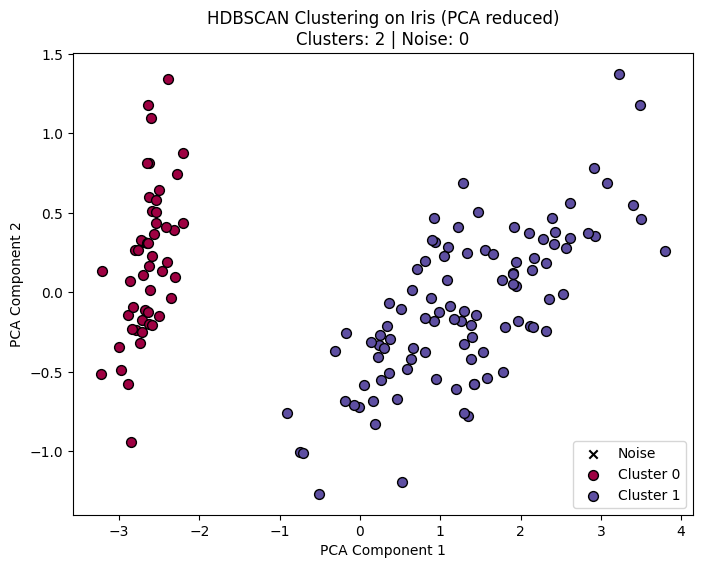

In [6]:
# Reduksi dimensi menggunakan PCA ke 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_iris)

# Visualisasi
plt.figure(figsize=(8, 6))

# Plot noise (label -1)
noise_idx = (labels_hdb == -1)
plt.scatter(X_pca[noise_idx, 0], X_pca[noise_idx, 1], c='black', marker='x', label='Noise')

# Plot clusters
unique_labels = set(labels_hdb) - {-1}
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    class_member_mask = (labels_hdb == k)
    plt.scatter(X_pca[class_member_mask, 0], X_pca[class_member_mask, 1],
                c=[col], marker='o', s=50, edgecolor='k', label=f'Cluster {k}')

plt.title(f'HDBSCAN Clustering on Iris (PCA reduced)\nClusters: {n_clusters_} | Noise: {n_noise_}')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()

**Label Asli**: Iris memiliki 3 kelas/label yang seimbang (Setosa, Versicolor, dan Virginica).

**Karakteristik HDBSCAN**: Pada sebagian besar setting default, HDBSCAN cenderung mengidentifikasi 2 cluster saja pada dataset Iris, bukan 3.

**Analisis**: Hal ini karena kelas Setosa terpisah sangat jauh secara jarak dan kepadatan, sehingga selalu berhasil dijadikan satu cluster independen. Namun, kelas Versicolor dan Virginica saling tumpang tindih (overlap) secara densitas. Karena HDBSCAN adalah algoritma berbasis kepadatan (density-based), algoritma ini melihat Versicolor dan Virginica sebagai satu massa kepadatan besar yang menyambung, sehingga menggabungkannya menjadi satu cluster dominan yang sama (dan menyisakan beberapa titik di perbatasan sebagai noise / dilabeli -1). Jadi, hasilnya tidak sepenuhnya sesuai dengan 3 label asli, tetapi merepresentasikan struktur topologi data Iris yang sebenarnya.